In [3]:
from __future__ import unicode_literals, print_function, division
from io import open
import unicodedata
import re
import random
import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F

import numpy as np
from torch.utils.data import TensorDataset, DataLoader, RandomSampler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [7]:
SOS_token = 0
EOS_token = 1

class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "SOS", 1: "EOS"}
        self.n_words = 2  # Count SOS and EOS

    def addSentence(self, sentence):
        for word in sentence.split(' '):
            self.addWord(word)

    def addWord(self, word):
        if word not in self.word2index:
            self.word2index[word] = self.n_words
            self.word2count[word] = 1
            self.index2word[self.n_words] = word
            self.n_words += 1
        else:
            self.word2count[word] += 1

In [8]:
# Turn a Unicode string to plain ASCII, thanks to
# https://stackoverflow.com/a/518232/2809427
def unicodeToAscii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

# Lowercase, trim, and remove non-letter characters
def normalizeString(s):
    s = unicodeToAscii(s.lower().strip())
    s = re.sub(r"([.!?])", r" \1", s)
    s = re.sub(r"[^a-zA-Z!?]+", r" ", s)
    return s.strip()

In [9]:
def readLangs(lang1, lang2, reverse=False):
    print("Reading lines...")

    # Read the file and split into lines
    lines = open('data/%s-%s.txt' % (lang1, lang2), encoding='utf-8').\
        read().strip().split('\n')

    # Split every line into pairs and normalize
    pairs = [[normalizeString(s) for s in l.split('\t')] for l in lines]

    # Reverse pairs, make Lang instances
    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang = Lang(lang2)
        output_lang = Lang(lang1)
    else:
        input_lang = Lang(lang1)
        output_lang = Lang(lang2)

    return input_lang, output_lang, pairs

In [11]:
MAX_LENGTH = 10

eng_prefixes = (
    "i am ", "i m ",
    "he is", "he s ",
    "she is", "she s ",
    "you are", "you re ",
    "we are", "we re ",
    "they are", "they re "
)

def filterPair(p):
    return len(p[0].split(' ')) < MAX_LENGTH and \
        len(p[1].split(' ')) < MAX_LENGTH and \
        p[1].startswith(eng_prefixes)


def filterPairs(pairs):
    return [pair for pair in pairs if filterPair(pair)]

In [12]:
def prepareData(lang1, lang2, reverse=False):
    input_lang, output_lang, pairs = readLangs(lang1, lang2, reverse)
    print("Read %s sentence pairs" % len(pairs))
    pairs = filterPairs(pairs)
    print("Trimmed to %s sentence pairs" % len(pairs))
    print("Counting words...")
    for pair in pairs:
        input_lang.addSentence(pair[0])
        output_lang.addSentence(pair[1])
    print("Counted words:")
    print(input_lang.name, input_lang.n_words)
    print(output_lang.name, output_lang.n_words)
    return input_lang, output_lang, pairs

input_lang, output_lang, pairs = prepareData('eng', 'fra', True)
print(random.choice(pairs))

Reading lines...
Read 135842 sentence pairs
Trimmed to 11445 sentence pairs
Counting words...
Counted words:
fra 4601
eng 2991
['ils sont en train de se disputer', 'they are arguing']


In [59]:
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size, dropout_p=0.1):
        super(EncoderRNN, self).__init__()
        self.hidden_size = hidden_size

        self.embedding = nn.Embedding(input_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, input):
        embedded = self.dropout(self.embedding(input))
        output, hidden = self.gru(embedded)
        return output, hidden

In [60]:
class DecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size):
        super(DecoderRNN, self).__init__()
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, output_size)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None):
        batch_size = encoder_outputs.size(0)
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=device).fill_(SOS_token)
        decoder_hidden = encoder_hidden
        decoder_outputs = []

        for i in range(MAX_LENGTH):
            decoder_output, decoder_hidden  = self.forward_step(decoder_input, decoder_hidden)
            decoder_outputs.append(decoder_output)

            if target_tensor is not None:
                # Teacher forcing: Feed the target as the next input
                decoder_input = target_tensor[:, i].unsqueeze(1) # Teacher forcing
            else:
                # Without teacher forcing: use its own predictions as the next input
                _, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach()  # detach from history as input

        decoder_outputs = torch.cat(decoder_outputs, dim=1)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1)
        return decoder_outputs, decoder_hidden, None # We return `None` for consistency in the training loop

    def forward_step(self, input, hidden):
        output = self.embedding(input)
        output = F.relu(output)
        output, hidden = self.gru(output, hidden)
        output = self.out(output)
        return output, hidden

In [13]:
class BahdanauAttention(nn.Module):
    def __init__(self, hidden_size):
        super(BahdanauAttention, self).__init__()
        self.Wa = nn.Linear(hidden_size, hidden_size)
        self.Ua = nn.Linear(hidden_size, hidden_size)
        self.Va = nn.Linear(hidden_size, 1)

    def forward(self, query, keys):
        scores = self.Va(torch.tanh(self.Wa(query) + self.Ua(keys)))
        scores = scores.squeeze(2).unsqueeze(1)

        weights = F.softmax(scores, dim=-1)
        context = torch.bmm(weights, keys)

        return context, weights

class AttnDecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.1):
        super(AttnDecoderRNN, self).__init__()
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.attention = BahdanauAttention(hidden_size)
        self.gru = nn.GRU(2 * hidden_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None):
        batch_size = encoder_outputs.size(0)
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=device).fill_(SOS_token)
        decoder_hidden = encoder_hidden
        decoder_outputs = []
        attentions = []

        for i in range(MAX_LENGTH):
            decoder_output, decoder_hidden, attn_weights = self.forward_step(
                decoder_input, decoder_hidden, encoder_outputs
            )
            decoder_outputs.append(decoder_output)
            attentions.append(attn_weights)

            if target_tensor is not None:
                # Teacher forcing: Feed the target as the next input
                decoder_input = target_tensor[:, i].unsqueeze(1) # Teacher forcing
            else:
                # Without teacher forcing: use its own predictions as the next input
                _, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach()  # detach from history as input

        decoder_outputs = torch.cat(decoder_outputs, dim=1)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1)
        attentions = torch.cat(attentions, dim=1)

        return decoder_outputs, decoder_hidden, attentions


    def forward_step(self, input, hidden, encoder_outputs):
        embedded =  self.dropout(self.embedding(input))

        query = hidden.permute(1, 0, 2)
        context, attn_weights = self.attention(query, encoder_outputs)
        input_gru = torch.cat((embedded, context), dim=2)

        output, hidden = self.gru(input_gru, hidden)
        output = self.out(output)

        return output, hidden, attn_weights

In [14]:
def indexesFromSentence(lang, sentence):
    return [lang.word2index[word] for word in sentence.split(' ')]

def tensorFromSentence(lang, sentence):
    indexes = indexesFromSentence(lang, sentence)
    indexes.append(EOS_token)
    return torch.tensor(indexes, dtype=torch.long, device=device).view(1, -1)

def tensorsFromPair(pair):
    input_tensor = tensorFromSentence(input_lang, pair[0])
    target_tensor = tensorFromSentence(output_lang, pair[1])
    return (input_tensor, target_tensor)

def get_dataloader(batch_size):
    input_lang, output_lang, pairs = prepareData('eng', 'fra', True)

    n = len(pairs)
    input_ids = np.zeros((n, MAX_LENGTH), dtype=np.int32)
    target_ids = np.zeros((n, MAX_LENGTH), dtype=np.int32)

    for idx, (inp, tgt) in enumerate(pairs):
        inp_ids = indexesFromSentence(input_lang, inp)
        tgt_ids = indexesFromSentence(output_lang, tgt)
        inp_ids.append(EOS_token)
        tgt_ids.append(EOS_token)
        input_ids[idx, :len(inp_ids)] = inp_ids
        target_ids[idx, :len(tgt_ids)] = tgt_ids

    train_data = TensorDataset(torch.LongTensor(input_ids).to(device),
                               torch.LongTensor(target_ids).to(device))

    train_sampler = RandomSampler(train_data)
    train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=batch_size)
    return input_lang, output_lang, train_dataloader

In [15]:
def train_epoch(dataloader, encoder, decoder, encoder_optimizer,
          decoder_optimizer, criterion):

    total_loss = 0
    for data in dataloader:
        input_tensor, target_tensor = data

        encoder_optimizer.zero_grad()
        decoder_optimizer.zero_grad()

        encoder_outputs, encoder_hidden = encoder(input_tensor)
        decoder_outputs, _, _ = decoder(encoder_outputs, encoder_hidden, target_tensor)

        loss = criterion(
            decoder_outputs.view(-1, decoder_outputs.size(-1)),
            target_tensor.view(-1)
        )
        loss.backward()

        encoder_optimizer.step()
        decoder_optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)

In [16]:
import time
import math

def asMinutes(s):
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)

def timeSince(since, percent):
    now = time.time()
    s = now - since
    es = s / (percent)
    rs = es - s
    return '%s (- %s)' % (asMinutes(s), asMinutes(rs))

In [17]:
def train(train_dataloader, encoder, decoder, n_epochs, learning_rate=0.001,
               print_every=100, plot_every=100):
    start = time.time()
    plot_losses = []
    print_loss_total = 0  # Reset every print_every
    plot_loss_total = 0  # Reset every plot_every

    encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
    decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate)
    criterion = nn.NLLLoss()

    for epoch in range(1, n_epochs + 1):
        loss = train_epoch(train_dataloader, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion)
        print_loss_total += loss
        plot_loss_total += loss

        if epoch % print_every == 0:
            print_loss_avg = print_loss_total / print_every
            print_loss_total = 0
            print('%s (%d %d%%) %.4f' % (timeSince(start, epoch / n_epochs),
                                        epoch, epoch / n_epochs * 100, print_loss_avg))

        if epoch % plot_every == 0:
            plot_loss_avg = plot_loss_total / plot_every
            plot_losses.append(plot_loss_avg)
            plot_loss_total = 0

    showPlot(plot_losses)

In [4]:
import matplotlib.pyplot as plt
# plt.switch_backend('agg')
import matplotlib.ticker as ticker
import numpy as np

def showPlot(points):
    fig, ax = plt.subplots()
    # this locator puts ticks at regular intervals
    loc = ticker.MultipleLocator(base=0.2)
    ax.yaxis.set_major_locator(loc)
    plt.plot(points)
    plt.show()

In [20]:
def evaluate(encoder, decoder, sentence, input_lang, output_lang):
    with torch.no_grad():
        input_tensor = tensorFromSentence(input_lang, sentence)

        encoder_outputs, encoder_hidden = encoder(input_tensor)
        decoder_outputs, decoder_hidden, decoder_attn = decoder(encoder_outputs, encoder_hidden)

        _, topi = decoder_outputs.topk(1)
        decoded_ids = topi.squeeze()

        decoded_words = []
        for idx in decoded_ids:
            if idx.item() == EOS_token:
                decoded_words.append('<EOS>')
                break
            decoded_words.append(output_lang.index2word[idx.item()])
    return decoded_words, decoder_attn

In [21]:
def evaluateRandomly(encoder, decoder, n=10):
    for i in range(n):
        pair = random.choice(pairs)
        print('>', pair[0])
        print('=', pair[1])
        output_words, _ = evaluate(encoder, decoder, pair[0], input_lang, output_lang)
        output_sentence = ' '.join(output_words)
        print('<', output_sentence)
        print('')

## Non-attending Encoder-Decoder

Reading lines...
Read 135842 sentence pairs
Trimmed to 11445 sentence pairs
Counting words...
Counted words:
fra 4601
eng 2991
0m 26s (- 6m 38s) (5 6%) 1.7249
0m 52s (- 6m 9s) (10 12%) 0.9815
1m 19s (- 5m 44s) (15 18%) 0.6785
1m 46s (- 5m 18s) (20 25%) 0.4921
2m 14s (- 4m 55s) (25 31%) 0.3659
2m 40s (- 4m 28s) (30 37%) 0.2767
3m 7s (- 4m 1s) (35 43%) 0.2147
3m 34s (- 3m 34s) (40 50%) 0.1697
4m 2s (- 3m 8s) (45 56%) 0.1366
4m 28s (- 2m 41s) (50 62%) 0.1122
4m 54s (- 2m 13s) (55 68%) 0.0937
5m 21s (- 1m 47s) (60 75%) 0.0805
5m 47s (- 1m 20s) (65 81%) 0.0700
6m 14s (- 0m 53s) (70 87%) 0.0616
6m 44s (- 0m 26s) (75 93%) 0.0560
7m 11s (- 0m 0s) (80 100%) 0.0503


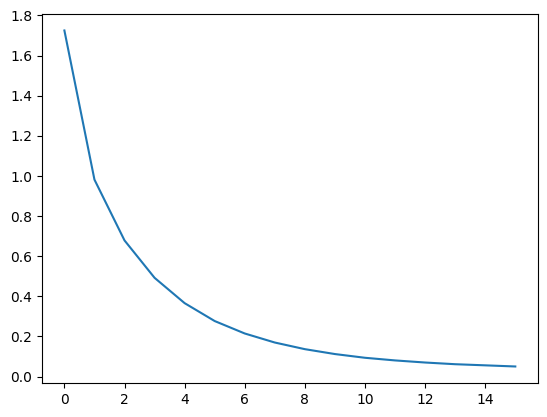

In [69]:
hidden_size = 128
batch_size = 32

input_lang, output_lang, train_dataloader = get_dataloader(batch_size)
encoder1 = EncoderRNN(input_lang.n_words, hidden_size).to(device)
decoder1 = DecoderRNN(hidden_size, output_lang.n_words).to(device)

train(train_dataloader, encoder1, decoder1, 80, print_every=5, plot_every=5)

In [70]:
encoder1.eval()
decoder1.eval()
evaluateRandomly(encoder1, decoder1)

> je n ai simplement pas tres faim
= i m just not very hungry
< i m just not very hungry <EOS>

> tu es le meilleur
= you re the best
< you re the tallest person <EOS>

> tu n y es pas en securite
= you re not safe here
< you re not safe here <EOS>

> je suis voyant
= i m psychic
< i m better at home <EOS>

> ca ne me fait pas du tout peur
= i m not in the least afraid of it
< i m not in the least afraid of it <EOS>

> vous avez tous deux faux
= you are both in the wrong
< you re both wrong <EOS>

> je ne suis pas entierement sure
= i m not entirely sure
< i m not entirely sure <EOS>

> je suis tres mediocre en sport
= i am very poor at sports
< i am very poor at sports <EOS>

> t es bonne
= you re good
< you re good at tennis <EOS>

> vous etes tres drole
= you re very funny
< you re very very funny <EOS>



## Encoder-Decoder with Attention

Reading lines...
Read 135842 sentence pairs
Trimmed to 11445 sentence pairs
Counting words...
Counted words:
fra 4601
eng 2991
0m 48s (- 12m 8s) (5 6%) 1.5583
1m 36s (- 11m 12s) (10 12%) 0.7016
2m 23s (- 10m 22s) (15 18%) 0.3677
3m 13s (- 9m 39s) (20 25%) 0.2052
4m 3s (- 8m 55s) (25 31%) 0.1268
4m 53s (- 8m 8s) (30 37%) 0.0871
5m 40s (- 7m 17s) (35 43%) 0.0665
6m 27s (- 6m 27s) (40 50%) 0.0537
7m 15s (- 5m 39s) (45 56%) 0.0463
8m 12s (- 4m 55s) (50 62%) 0.0413
9m 11s (- 4m 10s) (55 68%) 0.0377
10m 11s (- 3m 23s) (60 75%) 0.0355
11m 9s (- 2m 34s) (65 81%) 0.0339
12m 3s (- 1m 43s) (70 87%) 0.0313
12m 53s (- 0m 51s) (75 93%) 0.0302
13m 43s (- 0m 0s) (80 100%) 0.0296


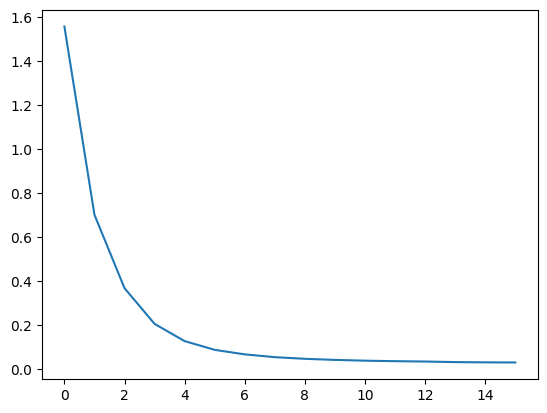

In [71]:
hidden_size = 128
batch_size = 32

input_lang, output_lang, train_dataloader = get_dataloader(batch_size)

encoder2 = EncoderRNN(input_lang.n_words, hidden_size).to(device)
decoder2 = AttnDecoderRNN(hidden_size, output_lang.n_words).to(device)

train(train_dataloader, encoder2, decoder2, 80, print_every=5, plot_every=5)

In [22]:
def showAttention(input_sentence, output_words, attentions):
    fig = plt.figure()
    ax = fig.add_subplot(111)
    cax = ax.matshow(attentions.cpu().numpy(), cmap='bone')
    fig.colorbar(cax)

    # Show label at every tick
    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))

    # Set up axes
    ax.set_xticklabels([''] + input_sentence.split(' ') +
                       ['<EOS>'], rotation=90)
    ax.set_yticklabels([''] + output_words)

    plt.show()

def evaluateAndShowAttention(input_sentence, encoder, decoder):
  output_words, attentions = evaluate(encoder, decoder, input_sentence, input_lang, output_lang)
  print('input =', input_sentence)
  print('output =', ' '.join(output_words))
  showAttention(input_sentence, output_words, attentions[0, :len(output_words), :])

> il est incompetent
= he is incompetent
< he is incompetent <EOS>

> elles sont decedees
= they re dead
< they re dead <EOS>

> vous etes pardonnees
= you re forgiven
< you re forgiven <EOS>

> je ne suis pas encore fatiguee
= i m not tired yet
< i m not tired yet <EOS>

> ce sont des garcons
= they re boys
< they re boys <EOS>

> je suis desole de vous avoir blessees
= i m sorry i hurt you
< i m sorry i hurt you <EOS>

> c est un moulin a parole
= she is a chatterbox
< she is a chatterbox <EOS>

> elle est ingenue
= she s innocent
< she s innocent <EOS>

> il est sur le point de mourir
= he is about to die
< he is about to die <EOS>

> je ne ressens pas particulierement la faim
= i m not feeling particularly hungry
< i m not feeling particularly hungry <EOS>

input = il n est pas aussi grand que son pere
output = he is not as tall as his father <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


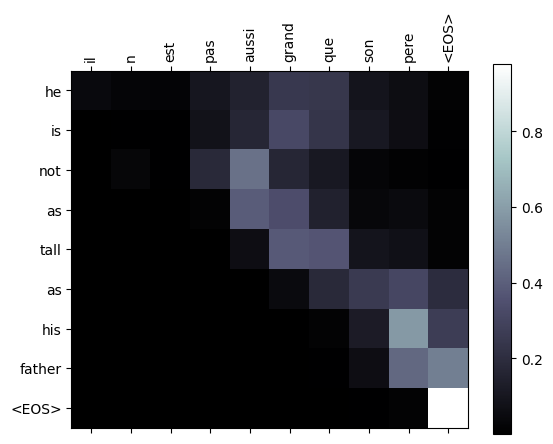

/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


input = je suis trop fatigue pour conduire
output = i m too tired to drive <EOS>


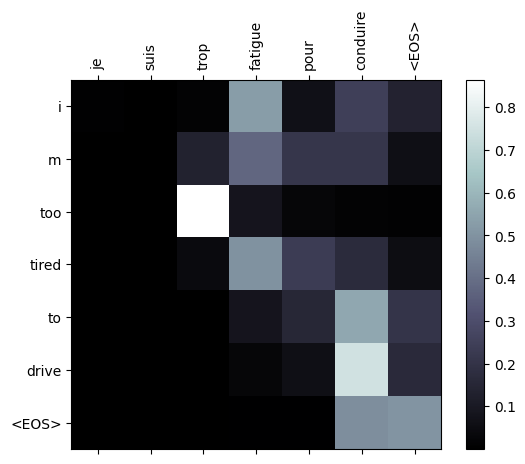

input = je suis desole si c est une question idiote
output = i m sorry if this is a stupid question <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


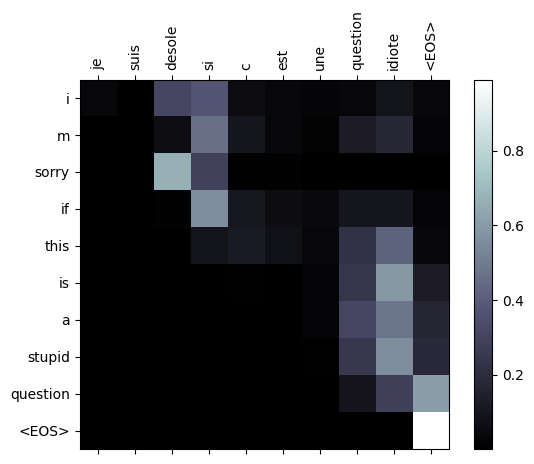

input = je suis reellement fiere de vous
output = i m really proud of you boston <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


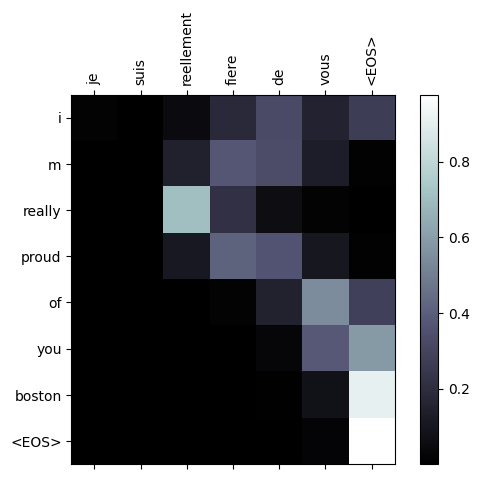

In [73]:
encoder2.eval()
decoder2.eval()
evaluateRandomly(encoder2, decoder2)

evaluateAndShowAttention(encoder=encoder2, decoder=decoder2, input_sentence='il n est pas aussi grand que son pere')

evaluateAndShowAttention(encoder=encoder2, decoder=decoder2, input_sentence='je suis trop fatigue pour conduire')

evaluateAndShowAttention(encoder=encoder2, decoder=decoder2, input_sentence='je suis desole si c est une question idiote')

evaluateAndShowAttention(encoder=encoder2, decoder=decoder2, input_sentence='je suis reellement fiere de vous')

## Encoder-Decoder with doubled hidden size

* training time: 2 minutes longer to train
* training loss: Much steeper loss curve. Whereas the 128 hidden size one didn't plateau till 25-30 epochs, this one does around 10. Otherwise it seems to be performing as well, according to the examples.


Reading lines...
Read 135842 sentence pairs
Trimmed to 11445 sentence pairs
Counting words...
Counted words:
fra 4601
eng 2991
0m 57s (- 14m 28s) (5 6%) 1.0874
1m 55s (- 13m 25s) (10 12%) 0.2125
2m 54s (- 12m 36s) (15 18%) 0.0714
3m 47s (- 11m 23s) (20 25%) 0.0476
4m 43s (- 10m 24s) (25 31%) 0.0402
5m 39s (- 9m 25s) (30 37%) 0.0361
6m 35s (- 8m 29s) (35 43%) 0.0341
7m 30s (- 7m 30s) (40 50%) 0.0328
8m 21s (- 6m 29s) (45 56%) 0.0308
9m 11s (- 5m 30s) (50 62%) 0.0300
10m 2s (- 4m 34s) (55 68%) 0.0296
10m 54s (- 3m 38s) (60 75%) 0.0283
11m 47s (- 2m 43s) (65 81%) 0.0282
12m 42s (- 1m 48s) (70 87%) 0.0274
13m 37s (- 0m 54s) (75 93%) 0.0273
14m 29s (- 0m 0s) (80 100%) 0.0271


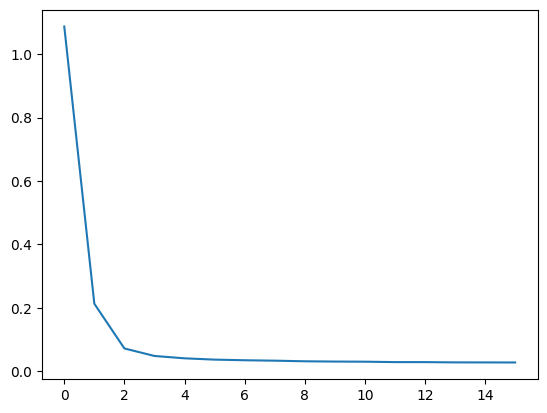

In [74]:
hidden_size = 256
batch_size = 32

input_lang, output_lang, train_dataloader = get_dataloader(batch_size)

encoder3 = EncoderRNN(input_lang.n_words, hidden_size).to(device)
decoder3 = AttnDecoderRNN(hidden_size, output_lang.n_words).to(device)

train(train_dataloader, encoder3, decoder3, 80, print_every=5, plot_every=5)

> tu es oublieux
= you re forgetful
< you re forgetful <EOS>

> vous n etes pas ma mere
= you re not my mother
< you aren t my mother <EOS>

> j ai bien peur de devoir y aller maintenant
= i m afraid i have to go now
< i m afraid i have to go now <EOS>

> c est un americain d origine asiatique
= he s an asian american
< he s an asian american <EOS>

> il est en chemin
= he s on his way
< he s on his way <EOS>

> ils attendent que vous les aidiez
= they are looking to you for help
< they are looking to you for help <EOS>

> elle a perdu ses cles de voiture
= she s lost her car keys
< she s lost her car keys <EOS>

> ils sont en danger
= they re in danger
< they re in danger <EOS>

> nous sommes devoues
= we re dedicated
< we re dedicated <EOS>

> vous ne m aidez pas
= you re not helping me
< you re not helping me <EOS>

input = il n est pas aussi grand que son pere
output = he is not as tall as his father <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


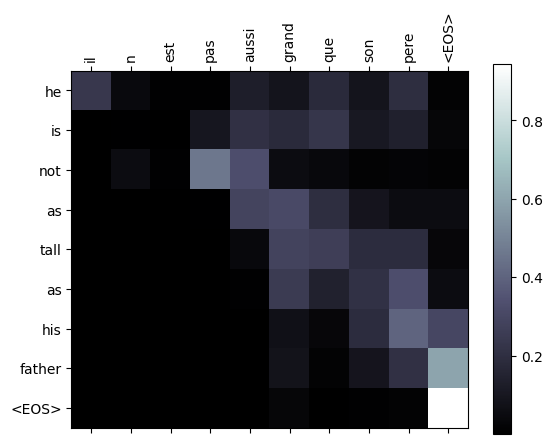

/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


input = je suis trop fatigue pour conduire
output = i m too tired to drive <EOS>


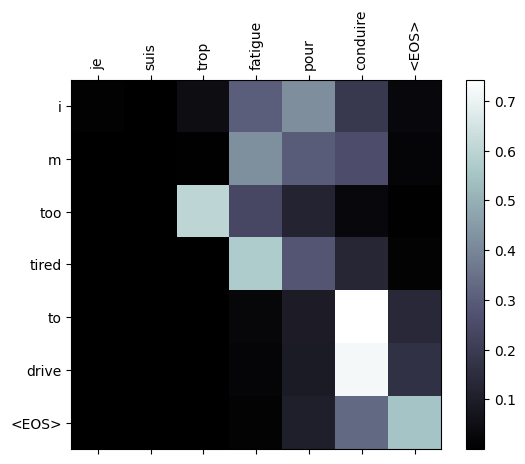

input = je suis desole si c est une question idiote
output = i m sorry if this is a stupid question <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


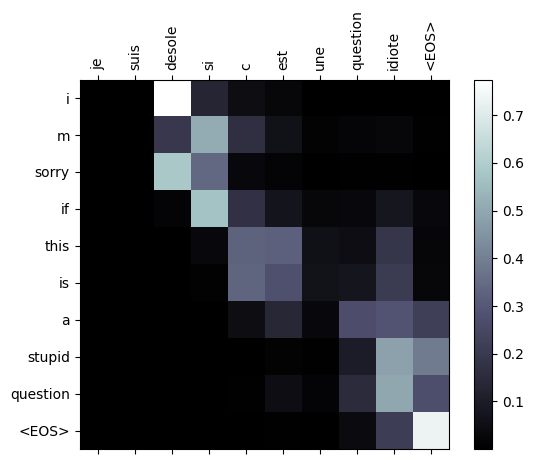

input = je suis reellement fiere de vous
output = i m really proud of you <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


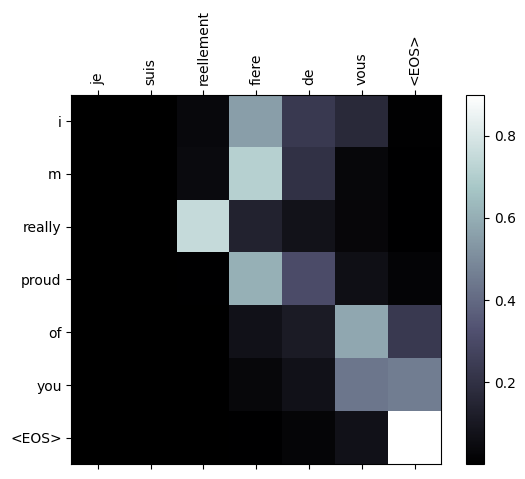

In [75]:
encoder3.eval()
decoder3.eval()
evaluateRandomly(encoder3, decoder3)

evaluateAndShowAttention(encoder=encoder3, decoder=decoder3, input_sentence='il n est pas aussi grand que son pere')

evaluateAndShowAttention(encoder=encoder3, decoder=decoder3, input_sentence='je suis trop fatigue pour conduire')

evaluateAndShowAttention(encoder=encoder3, decoder=decoder3, input_sentence='je suis desole si c est une question idiote')

evaluateAndShowAttention(encoder=encoder3, decoder=decoder3, input_sentence='je suis reellement fiere de vous')

## Encoder-Decoder with more layers

* training time: 5 minutes longer to train compared to the less-layered model.
* loss: noticeably less steep training curve and results that are much more questionable... and comically so. The less-layered model is preferable.
> \> je suis gros
= i m fat
< i m busy home

In [76]:
class EncoderRNN2(nn.Module):
    def __init__(self, input_size, hidden_size, dropout_p=0.1):
        super(EncoderRNN2, self).__init__()
        self.hidden_size = hidden_size

        self.embedding = nn.Embedding(input_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, num_layers=3, batch_first=True)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, input):
        embedded = self.dropout(self.embedding(input))
        output, hidden = self.gru(embedded)
        return output, hidden

class AttnDecoderRNN2(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.1):
        super(AttnDecoderRNN2, self).__init__()
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.attention = BahdanauAttention(hidden_size)
        self.gru = nn.GRU(2 * hidden_size, hidden_size, num_layers=3, batch_first=True)
        self.out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None):
        batch_size = encoder_outputs.size(0)
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=device).fill_(SOS_token)
        decoder_hidden = encoder_hidden
        decoder_outputs = []
        attentions = []

        for i in range(MAX_LENGTH):
            decoder_output, decoder_hidden, attn_weights = self.forward_step(
                decoder_input, decoder_hidden, encoder_outputs
            )
            decoder_outputs.append(decoder_output)
            attentions.append(attn_weights)

            if target_tensor is not None:
                # Teacher forcing: Feed the target as the next input
                decoder_input = target_tensor[:, i].unsqueeze(1) # Teacher forcing
            else:
                # Without teacher forcing: use its own predictions as the next input
                _, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach()  # detach from history as input

        decoder_outputs = torch.cat(decoder_outputs, dim=1)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1)
        attentions = torch.cat(attentions, dim=1)

        return decoder_outputs, decoder_hidden, attentions


    def forward_step(self, input, hidden, encoder_outputs):
        embedded =  self.dropout(self.embedding(input))

        # need only the top hidden layer's state
        query = hidden[-1:].permute(1, 0, 2)
        context, attn_weights = self.attention(query, encoder_outputs)
        input_gru = torch.cat((embedded, context), dim=2)

        output, hidden = self.gru(input_gru, hidden)
        output = self.out(output)

        return output, hidden, attn_weights

Reading lines...
Read 135842 sentence pairs
Trimmed to 11445 sentence pairs
Counting words...
Counted words:
fra 4601
eng 2991
1m 5s (- 16m 28s) (5 6%) 1.8311
2m 13s (- 15m 37s) (10 12%) 1.0094
3m 23s (- 14m 41s) (15 18%) 0.6435
4m 34s (- 13m 44s) (20 25%) 0.4153
5m 39s (- 12m 26s) (25 31%) 0.2698
6m 42s (- 11m 10s) (30 37%) 0.1799
7m 45s (- 9m 58s) (35 43%) 0.1247
8m 51s (- 8m 51s) (40 50%) 0.0925
9m 57s (- 7m 44s) (45 56%) 0.0729
11m 0s (- 6m 36s) (50 62%) 0.0624
12m 3s (- 5m 28s) (55 68%) 0.0544
13m 8s (- 4m 22s) (60 75%) 0.0499
14m 11s (- 3m 16s) (65 81%) 0.0452
15m 13s (- 2m 10s) (70 87%) 0.0434
16m 17s (- 1m 5s) (75 93%) 0.0413
17m 21s (- 0m 0s) (80 100%) 0.0398


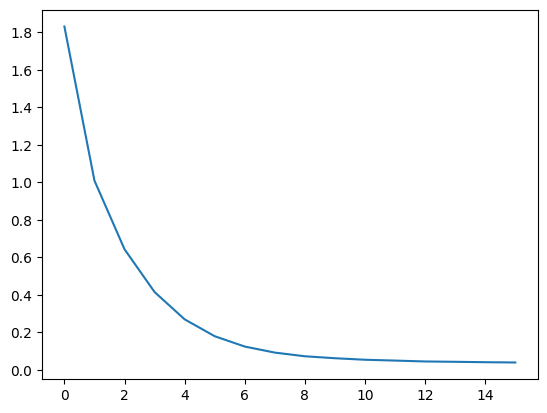

In [77]:
hidden_size = 128
batch_size = 32

input_lang, output_lang, train_dataloader = get_dataloader(batch_size)

encoder4 = EncoderRNN2(input_lang.n_words, hidden_size).to(device)
decoder4 = AttnDecoderRNN2(hidden_size, output_lang.n_words).to(device)

train(train_dataloader, encoder4, decoder4, 80, print_every=5, plot_every=5)

> je crains que nous ne puissions vous aider
= i m afraid we can t help you
< i m afraid we can t help you <EOS>

> je suis gros
= i m fat
< i m busy home <EOS>

> je vais devoir me teindre les cheveux
= i m going to have to dye my hair
< i m going to have to change my schedule <EOS>

> il est ce qu on appelle un pionnier
= he is what we call a pioneer
< he is what we call a pioneer <EOS>

> je suis vraiment decu
= i m really disappointed
< i m really not your teacher <EOS>

> elle est obstinee
= she is obstinate
< she just strong willed <EOS>

> en realite il n est pas le gerant
= he is actually not the manager
< he is actually not the manager <EOS>

> je suis accoutume au temps froid
= i am accustomed to cold weather
< i am accustomed to working hard long <EOS>

> vous etes deux fois plus forts que moi
= you are twice as strong as i am
< you are twice as strong as me <EOS>

> vous passez trop de temps a regarder la tele
= you re spending too much time watching tv
< you re spending to

/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


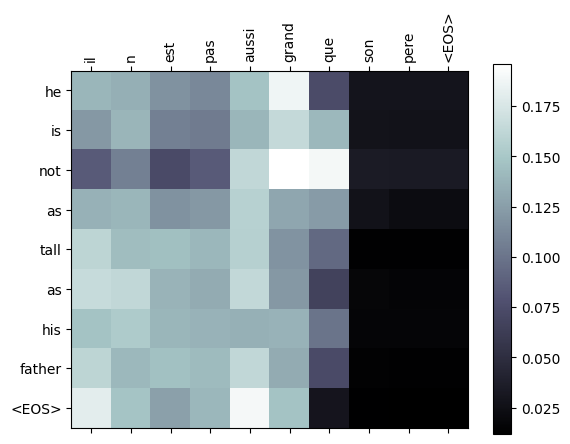

input = je suis trop fatigue pour conduire
output = i m too tired to walk any further <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


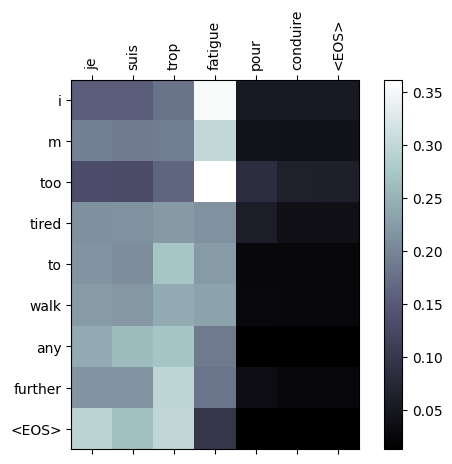

input = je suis desole si c est une question idiote
output = i m sorry if this is a stupid question <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


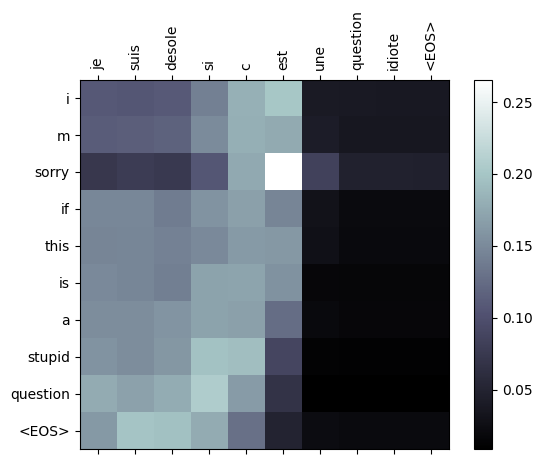

input = je suis reellement fiere de vous
output = i m really glad you re done <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


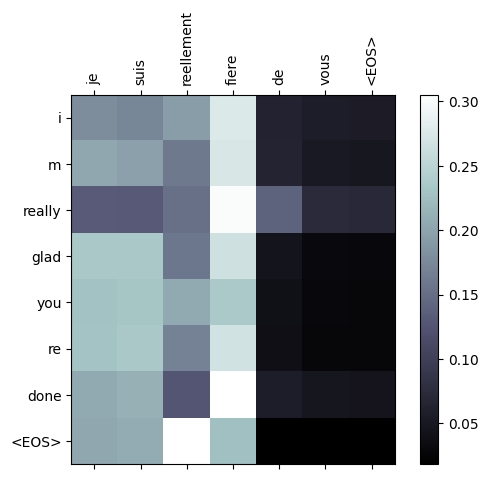

In [78]:
encoder4.eval()
decoder4.eval()
evaluateRandomly(encoder4, decoder4)

evaluateAndShowAttention(encoder=encoder4, decoder=decoder4, input_sentence='il n est pas aussi grand que son pere')

evaluateAndShowAttention(encoder=encoder4, decoder=decoder4, input_sentence='je suis trop fatigue pour conduire')

evaluateAndShowAttention(encoder=encoder4, decoder=decoder4, input_sentence='je suis desole si c est une question idiote')

evaluateAndShowAttention(encoder=encoder4, decoder=decoder4, input_sentence='je suis reellement fiere de vous')

## Encoder-Decoder with more layers & doubled hidden size

* training time: about a minute longer training time than the non-doubled hidden size version.
* loss: steeper training curve, still worse performance than the models with less layers. Also comically bad in some instances.
> \> vous etes tres timides
= you re very timid
< you re very very attractive in blue <EOS>

Reading lines...
Read 135842 sentence pairs
Trimmed to 11445 sentence pairs
Counting words...
Counted words:
fra 4601
eng 2991
1m 8s (- 17m 2s) (5 6%) 1.4871
2m 15s (- 15m 49s) (10 12%) 0.5022
3m 24s (- 14m 45s) (15 18%) 0.1575
4m 36s (- 13m 50s) (20 25%) 0.0685
5m 45s (- 12m 39s) (25 31%) 0.0530
6m 53s (- 11m 28s) (30 37%) 0.0452
8m 3s (- 10m 21s) (35 43%) 0.0431
9m 12s (- 9m 12s) (40 50%) 0.0392
10m 19s (- 8m 1s) (45 56%) 0.0380
11m 27s (- 6m 52s) (50 62%) 0.0377
12m 38s (- 5m 44s) (55 68%) 0.0368
13m 48s (- 4m 36s) (60 75%) 0.0361
14m 57s (- 3m 27s) (65 81%) 0.0353
16m 7s (- 2m 18s) (70 87%) 0.0348
17m 18s (- 1m 9s) (75 93%) 0.0349
18m 27s (- 0m 0s) (80 100%) 0.0347


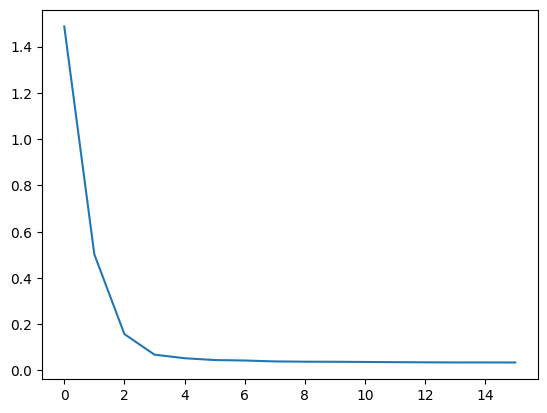

In [79]:
hidden_size = 256
batch_size = 32

input_lang, output_lang, train_dataloader = get_dataloader(batch_size)

encoder5 = EncoderRNN2(input_lang.n_words, hidden_size).to(device)
decoder5 = AttnDecoderRNN2(hidden_size, output_lang.n_words).to(device)

train(train_dataloader, encoder5, decoder5, 80, print_every=5, plot_every=5)

> vous etes tres timides
= you re very timid
< you re very very attractive in blue <EOS>

> je n ai pas termine
= i m not done
< i m not finished with it <EOS>

> je ne suis pas tres occupe
= i m not very busy
< i m not very very busy right now <EOS>

> je suis convaincu que tom est serieux
= i m pretty sure tom s serious
< i m pretty sure tom had a wonderful girl <EOS>

> je suis finlandais mais je parle aussi suedois
= i am finnish but i speak also swedish
< i am finnish but i speak also swedish <EOS>

> je suis certain que tu reussiras
= i m sure that you ll succeed
< i m sure you ve done <EOS>

> t es bourree
= you re loaded
< you re loaded <EOS>

> tu es veinarde
= you re in luck
< you re in the whole picture <EOS>

> il est plus fort que vous
= he s stronger than you
< he s stronger than you <EOS>

> c est le portrait crache de son pere
= he is the spitting image of his father
< he is the image of his father <EOS>

input = il n est pas aussi grand que son pere
output = he is not 

/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


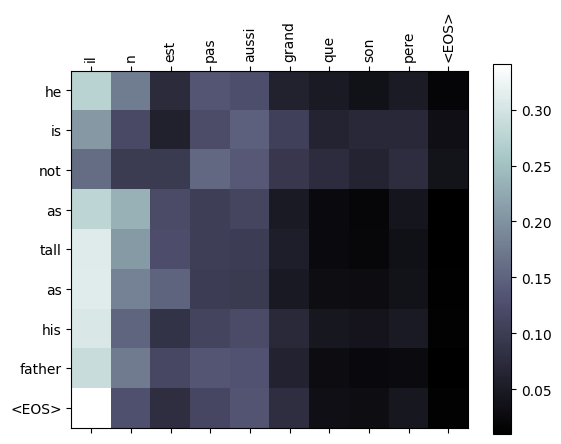

input = je suis trop fatigue pour conduire
output = i m too tired to make i m boston <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


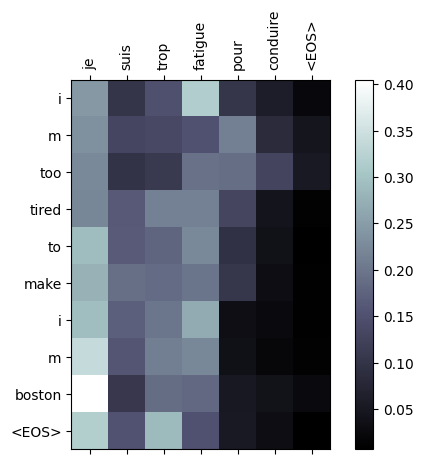

input = je suis desole si c est une question idiote
output = i m sorry if this is a stupid question <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


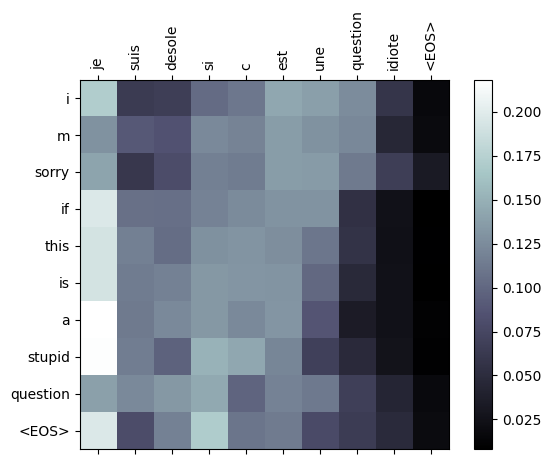

input = je suis reellement fiere de vous
output = i m really glad to hear you <EOS>


/tmp/ipykernel_6217/1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
/tmp/ipykernel_6217/1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + output_words)


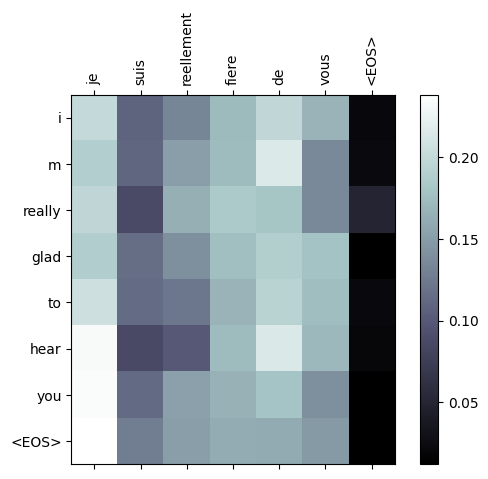

In [80]:
encoder5.eval()
decoder5.eval()
evaluateRandomly(encoder5, decoder5)

evaluateAndShowAttention(encoder=encoder5, decoder=decoder5, input_sentence='il n est pas aussi grand que son pere')

evaluateAndShowAttention(encoder=encoder5, decoder=decoder5, input_sentence='je suis trop fatigue pour conduire')

evaluateAndShowAttention(encoder=encoder5, decoder=decoder5, input_sentence='je suis desole si c est une question idiote')

evaluateAndShowAttention(encoder=encoder5, decoder=decoder5, input_sentence='je suis reellement fiere de vous')

## Encoder-Decoder using Pretrained Embeddings

* train time: Extremely fast (at least 3x faster than previous models) especially considering that it was done on a CPU unlike the previous models which were on a GPU. I would guess it's because the pretrained embedding gave such a big 'head start' to the model, but technically, I don't know how that it would be that significant.
* training loss: Looks pretty normal, the performance isn't perfect either but is fair enough. Also a few of the attention visualization didn't work because the words weren't in the embedding matrix. Not sure how that's possible since I had it iterate over the pairs from the tutorial's prepare function. (NOTE: If you want to run the below cell, it may be faster to just download the fasttext bin file from: https://fasttext.cc/docs/en/crawl-vectors.html)

In [ ]:
import fasttext.util

# get both english and french fast text models
fasttext.util.download_model('en', if_exists='ignore')
fasttext.util.download_model('fr', if_exists='ignore')

ft_en = fasttext.load_model('cc.en.300.bin')
ft_fr = fasttext.load_model('cc.fr.300.bin')

In [23]:
# Adjust the tokenization slightly to match fast text
def normalizeString(s):
    s = unicodeToAscii(s.lower().strip())

    # 1. Pad common punctuation marks with spaces on both sides.
    # This treats them as independent tokens (which fastText expects)
    # (this was done by gemini, not me. I don't know regex well enough...)
    s = re.sub(r"([.!?,\'\"\(\)])", r" \1 ", s)

    s = re.sub(r"[^a-zA-Z0-9.!?,\'\"\(\)]+", r" ", s)

    return s.strip()

# Pre-retrieve all the needed embeddings so that it the model doesn't have to during training; rather, it can
# just quickly lookup in the tables what the embedding is
embedding_dim = 300
input_lang, output_lang, pairs = prepareData('eng', 'fra', True)

input_embeds = torch.zeros((input_lang.n_words, embedding_dim)).to(device)
for idx in range(input_lang.n_words):
  word = input_lang.index2word[idx]
  input_embeds[idx] = torch.tensor(ft_fr.get_word_vector(word))

output_embeds = torch.zeros((output_lang.n_words, embedding_dim)).to(device)
for idx in range(output_lang.n_words):
  word = output_lang.index2word[idx]
  output_embeds[idx] = torch.tensor(ft_en.get_word_vector(word))



Reading lines...
Read 135842 sentence pairs
Trimmed to 2417 sentence pairs
Counting words...
Counted words:
fra 1893
eng 1459


In [24]:
class EncoderRNN3(nn.Module):
    def __init__(self, input_size, hidden_size, pretrained_embeds, dropout_p=0.1):
        super(EncoderRNN3, self).__init__()
        self.hidden_size = hidden_size

        self.embedding = nn.Embedding.from_pretrained(pretrained_embeds, freeze=True)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, input):
        embedded = self.dropout(self.embedding(input))
        output, hidden = self.gru(embedded)
        return output, hidden

class AttnDecoderRNN3(nn.Module):
    def __init__(self, hidden_size, output_size, pretrained_embeds, dropout_p=0.1):
        super(AttnDecoderRNN3, self).__init__()
        self.embedding = nn.Embedding.from_pretrained(pretrained_embeds, freeze=True)
        self.attention = BahdanauAttention(hidden_size)
        self.gru = nn.GRU(2 * hidden_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(dropout_p)

    def forward(self, encoder_outputs, encoder_hidden, target_tensor=None):
        batch_size = encoder_outputs.size(0)
        decoder_input = torch.empty(batch_size, 1, dtype=torch.long, device=device).fill_(SOS_token)
        decoder_hidden = encoder_hidden
        decoder_outputs = []
        attentions = []

        for i in range(MAX_LENGTH):
            decoder_output, decoder_hidden, attn_weights = self.forward_step(
                decoder_input, decoder_hidden, encoder_outputs
            )
            decoder_outputs.append(decoder_output)
            attentions.append(attn_weights)

            if target_tensor is not None:
                # Teacher forcing: Feed the target as the next input
                decoder_input = target_tensor[:, i].unsqueeze(1) # Teacher forcing
            else:
                # Without teacher forcing: use its own predictions as the next input
                _, topi = decoder_output.topk(1)
                decoder_input = topi.squeeze(-1).detach()  # detach from history as input

        decoder_outputs = torch.cat(decoder_outputs, dim=1)
        decoder_outputs = F.log_softmax(decoder_outputs, dim=-1)
        attentions = torch.cat(attentions, dim=1)

        return decoder_outputs, decoder_hidden, attentions


    def forward_step(self, input, hidden, encoder_outputs):
        embedded =  self.dropout(self.embedding(input))

        query = hidden.permute(1, 0, 2)
        context, attn_weights = self.attention(query, encoder_outputs)
        input_gru = torch.cat((embedded, context), dim=2)

        output, hidden = self.gru(input_gru, hidden)
        output = self.out(output)

        return output, hidden, attn_weights

Reading lines...
Read 135842 sentence pairs
Trimmed to 2417 sentence pairs
Counting words...
Counted words:
fra 1893
eng 1459
0m 18s (- 4m 41s) (5 6%) 2.1615
0m 31s (- 3m 43s) (10 12%) 1.2479
0m 45s (- 3m 16s) (15 18%) 0.8076
0m 58s (- 2m 55s) (20 25%) 0.4981
1m 11s (- 2m 37s) (25 31%) 0.2988
1m 24s (- 2m 21s) (30 37%) 0.1759
1m 38s (- 2m 6s) (35 43%) 0.1078
1m 51s (- 1m 51s) (40 50%) 0.0690
2m 4s (- 1m 37s) (45 56%) 0.0511
2m 18s (- 1m 23s) (50 62%) 0.0362
2m 31s (- 1m 8s) (55 68%) 0.0304
2m 44s (- 0m 54s) (60 75%) 0.0246
2m 58s (- 0m 41s) (65 81%) 0.0363
3m 11s (- 0m 27s) (70 87%) 0.0201
3m 24s (- 0m 13s) (75 93%) 0.0176
3m 37s (- 0m 0s) (80 100%) 0.0163


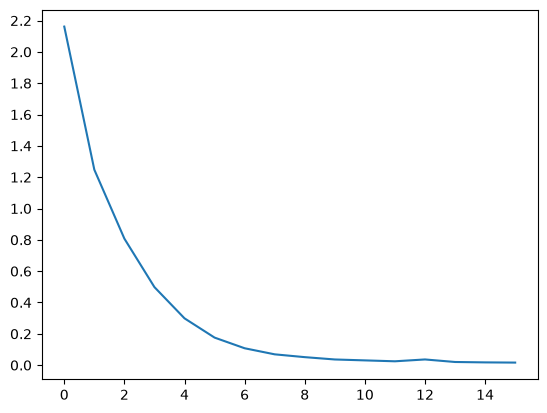

In [25]:
hidden_size = 300
batch_size = 32

input_lang, output_lang, train_dataloader = get_dataloader(batch_size)

encoder6 = EncoderRNN3(input_lang.n_words, hidden_size, input_embeds).to(device)
decoder6 = AttnDecoderRNN3(hidden_size, output_lang.n_words, output_embeds).to(device)

train(train_dataloader, encoder6, decoder6, 80, print_every=5, plot_every=5)

> ils sont dingues de jazz .
= they are crazy about jazz .
< they are crazy about jazz . <EOS>

> ils sont sur le point de commencer .
= they are about to start .
< they are about to start . <EOS>

> elle est extremement seduisante .
= she is extremely attractive .
< she is very pretty to have alone . <EOS>

> il est responsable de l ' accident .
= he is responsible for the accident .
< he is responsible for the accident . <EOS>

> elle est morte .
= she is dead .
< she is dead . <EOS>

> ce sont mes amies .
= they are my friends .
< they are my friends . <EOS>

> elle est vraiment attentive et patiente .
= she is very thoughtful and patient .
< she is very thoughtful and patient . <EOS>

> tu es un bon garcon .
= you are a good boy .
< you are a good boy . <EOS>

> pour une fois j ' ai raison .
= i am right for once .
< i am right for once . <EOS>

> elle parle bien anglais .
= she is a good english speaker .
< she is very thoughtful and a walk . <EOS>

input = il n est pas aussi gran

C:\Users\dillo\AppData\Local\Temp\ipykernel_33852\1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
C:\Users\dillo\AppData\Local\Temp\ipykernel_33852\1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([''] + output_words)


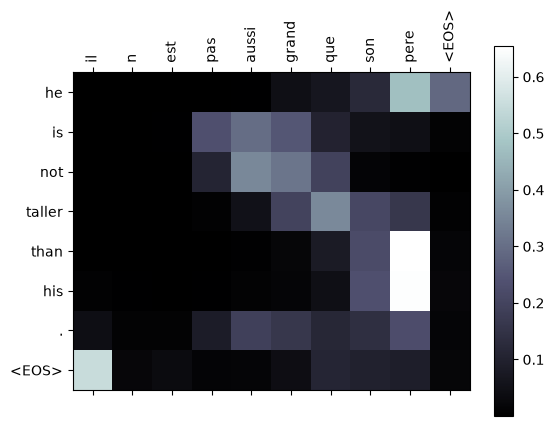

input = je suis trop fatigue pour conduire
output = i am too tired to run alone . <EOS>


C:\Users\dillo\AppData\Local\Temp\ipykernel_33852\1649676944.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([''] + input_sentence.split(' ') +
C:\Users\dillo\AppData\Local\Temp\ipykernel_33852\1649676944.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([''] + output_words)


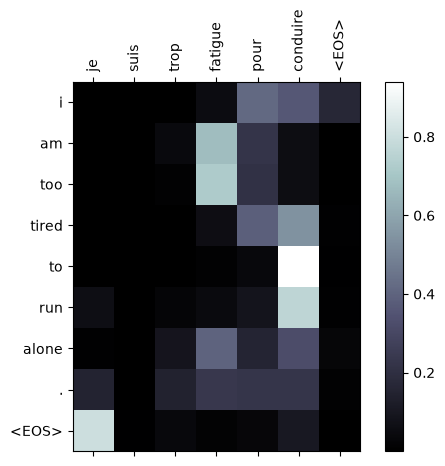

In [28]:
encoder6.eval()
decoder6.eval()
evaluateRandomly(encoder6, decoder6)

evaluateAndShowAttention(encoder=encoder6, decoder=decoder6, input_sentence='il n est pas aussi grand que son pere')

evaluateAndShowAttention(encoder=encoder6, decoder=decoder6, input_sentence='je suis trop fatigue pour conduire')
